In [15]:
import os 
import functions
import mirdata
import librosa
import pandas as pd
import matplotlib.pyplot as plt
import mir_eval
import numpy as np
from tqdm import tqdm

In [8]:
ballroom = mirdata.initialize('ballroom')
# ballroom.download()
# ballroom.validate()
track_ids = ballroom.track_ids

In [9]:
# Split the prepared dataset into train and test sets (reproducible)
test_size = 0.3
seed = 42

track_ids_shuffled = track_ids.copy()
np.random.seed(seed)
np.random.shuffle(track_ids_shuffled)

split_idx = int(len(track_ids_shuffled) * (1 - test_size))
train_track_ids = track_ids_shuffled[:split_idx]
test_track_ids = track_ids_shuffled[split_idx:]

print(f"Train size: {len(train_track_ids)}")
print(f"Test size: {len(test_track_ids)}")

Train size: 488
Test size: 210


Track: Albums-Fire-10.wav
Style: Rumba-International
Ground Truth BPM: 100.0, 
Estimated BPM: 99, 
Estimated BPM Refined: 197
Absolute Error BPM: 1.0
Absolute Error BPM Refined: 97.0


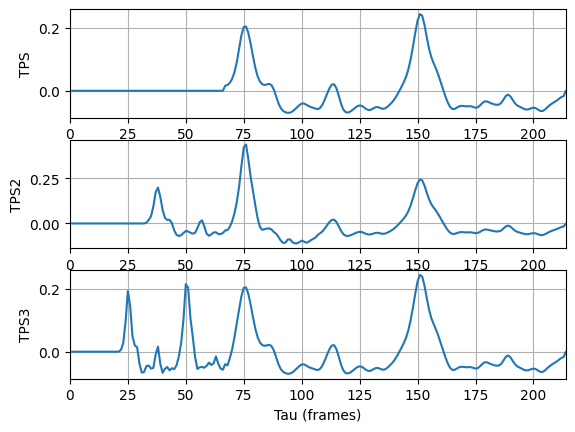

In [14]:
hop_time = 0.004
track_id = train_track_ids[10]
track = ballroom.track(track_id)
split_path = track.audio_path.replace("\\", "/").split("/")
track_name = split_path[-1]
track_style = split_path[-2]
bpm = track.tempo
metre = np.max(track.beats.positions)
onset_strength = functions.get_onset_strength(track.audio_path)
primary_tempo_samples = functions.estimate_tempo(onset_strength)
estimated_bpm = round(60 / (primary_tempo_samples * hop_time))
metre, primary_tempo_samples_refined = functions.estimate_tempo_and_division(onset_strength, sigma_t=1.4, plot=True)
estimated_bpm_refined = round(60 / (primary_tempo_samples_refined * hop_time))
absolute_error_bpm = abs(estimated_bpm - bpm)
absolute_error_bpm_refined = abs(estimated_bpm_refined - bpm)
print(f"Track: {track_name}")
print(f"Style: {track_style}")
print(f"Ground Truth BPM: {bpm}, ")
print(f"Estimated BPM: {estimated_bpm}, ")
print(f"Estimated BPM Refined: {estimated_bpm_refined}")
print(f"Absolute Error BPM: {absolute_error_bpm}")
print(f"Absolute Error BPM Refined: {absolute_error_bpm_refined}")

In [6]:
sigmas = np.arange(0.5, 2, 0.2)
sigmas

array([0.5, 0.7, 0.9, 1.1, 1.3, 1.5, 1.7, 1.9])

Find optimal sigmas:

In [17]:
train_df = pd.DataFrame(columns=["track_name", "track_style", "bpm", "absolute_error_bpm", "absolute_error_bpm_refined",
                                 "relative_error_bpm", "relative_error_bpm_refined"])

hop_time = 0.004
mae_basic = []
mae_refined = []
mre_basic = []
mre_refined = []

for sigma in sigmas:
    for i, track_id in enumerate(tqdm(train_track_ids)):
        track = ballroom.track(track_id)
        split_path = track.audio_path.replace("\\", "/").split("/")
        track_name = split_path[-1]
        track_style = split_path[-2]
        bpm = track.tempo
        onset_strength = functions.get_onset_strength(track.audio_path)
        primary_tempo_samples = functions.estimate_tempo(onset_strength, sigma_t=sigma)
        estimated_bpm = 60 / (primary_tempo_samples * hop_time)
        _, primary_tempo_samples_refined = functions.estimate_tempo_and_division(onset_strength, sigma_t=sigma)
        estimated_bpm_refined = 60 / (primary_tempo_samples_refined * hop_time)
        absolute_error_bpm = abs(estimated_bpm - bpm)
        relative_error_bpm = absolute_error_bpm / bpm
        absolute_error_bpm_refined = abs(estimated_bpm_refined - bpm)
        relative_error_bpm_refined = absolute_error_bpm_refined / bpm
        train_df.loc[i] = [track_name, track_style, bpm, absolute_error_bpm, absolute_error_bpm_refined, 
                           relative_error_bpm, relative_error_bpm_refined]
    mae_basic.append(train_df["absolute_error_bpm"].mean())
    mae_refined.append(train_df["absolute_error_bpm_refined"].mean())
    mre_basic.append(train_df["relative_error_bpm"].mean())
    mre_refined.append(train_df["relative_error_bpm_refined"].mean())

100%|██████████| 488/488 [01:57<00:00,  4.16it/s]


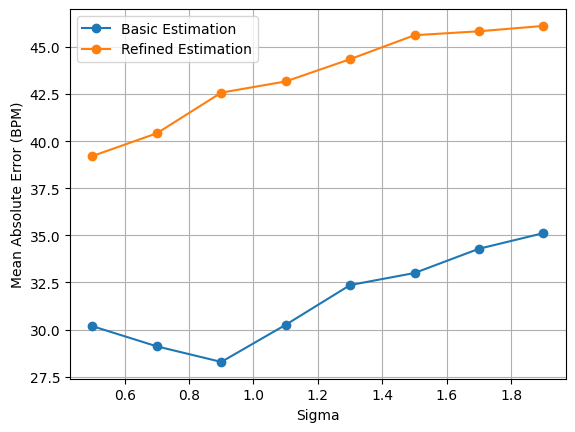

In [18]:
plt.figure()
plt.plot(sigmas, mae_basic, marker="o", label="Basic Estimation")
plt.plot(sigmas, mae_refined, marker="o", label="Refined Estimation")
plt.xlabel("Sigma")
plt.ylabel("Mean Absolute Error (BPM)")
plt.legend()
plt.grid()
plt.show()

In [21]:
train_df = pd.DataFrame(columns=["track_name", "track_style", "bpm", "absolute_error_bpm", 
    "absolute_error_bpm_refined", "relative_error_bpm", "relative_error_bpm_refined"])

for i, track_id in enumerate(tqdm(train_track_ids)):
    track = ballroom.track(track_id)
    split_path = track.audio_path.replace("\\", "/").split("/")
    track_name = split_path[-1]
    track_style = split_path[-2]
    bpm = track.tempo
    onset_strength = functions.get_onset_strength(track.audio_path)
    primary_tempo_samples = functions.estimate_tempo(onset_strength, sigma_t=0.9)
    estimated_bpm = 60 / (primary_tempo_samples * hop_time)
    _, primary_tempo_samples_refined = functions.estimate_tempo_and_division(onset_strength, sigma_t=0.5)
    estimated_bpm_refined = 60 / (primary_tempo_samples_refined * hop_time)
    absolute_error_bpm = abs(estimated_bpm - bpm)
    absolute_error_bpm_refined = abs(estimated_bpm_refined - bpm)
    relative_error_bpm = absolute_error_bpm / bpm
    relative_error_bpm_refined = absolute_error_bpm_refined / bpm
    train_df.loc[i] = [track_name, track_style, bpm, absolute_error_bpm, absolute_error_bpm_refined, relative_error_bpm, relative_error_bpm_refined]

  2%|▏         | 8/488 [00:01<01:51,  4.31it/s]

100%|██████████| 488/488 [01:38<00:00,  4.96it/s]


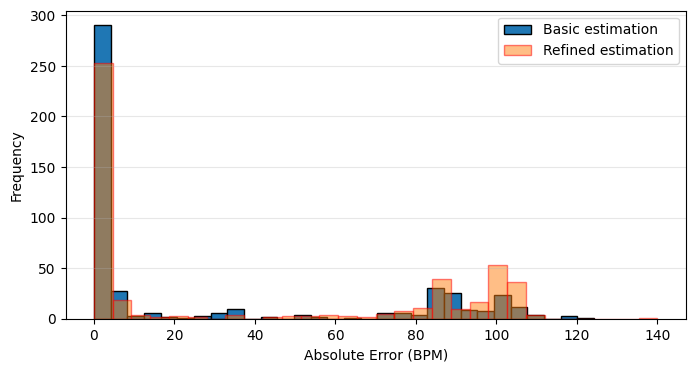

In [24]:
plt.figure(figsize=(8, 4))
train_df["absolute_error_bpm"].plot.hist(bins=30, edgecolor="black")
train_df["absolute_error_bpm_refined"].plot.hist(bins=30, edgecolor="red", alpha=0.5)
plt.xlabel("Absolute Error (BPM)")
plt.legend(["Basic estimation", "Refined estimation"])
plt.grid(axis="y", alpha=0.3)
plt.show()

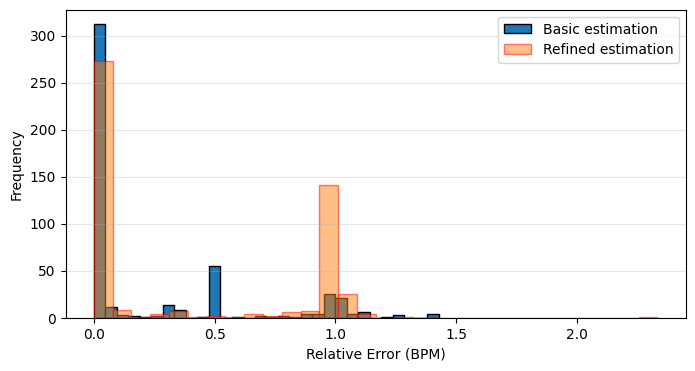

In [25]:
plt.figure(figsize=(8, 4))
train_df["relative_error_bpm"].plot.hist(bins=30, edgecolor="black")
train_df["relative_error_bpm_refined"].plot.hist(bins=30, edgecolor="red", alpha=0.5)
plt.xlabel("Relative Error (BPM)")
plt.legend(["Basic estimation", "Refined estimation"])
plt.grid(axis="y", alpha=0.3)
plt.show()

Track: Media-105207.wav
Style: Quickstep
Ground Truth BPM: 219.0, 
Estimated BPM: 211.2676056338028, 
Estimated BPM Refined: 108.69565217391303
Absolute Error BPM: 7.732394366197212
Absolute Error BPM Refined: 110.30434782608697


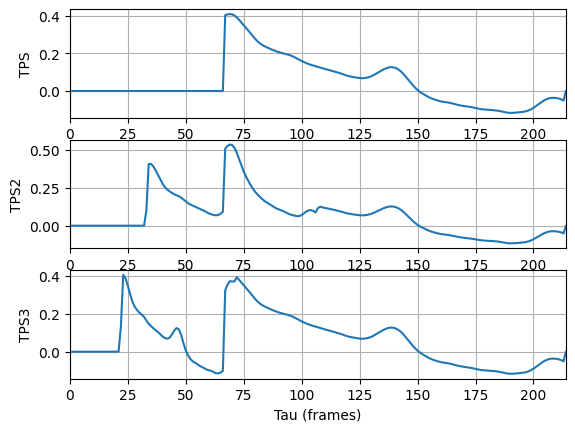

In [26]:
max_error_index = train_df["mean_absolute_error_bpm_refined"].idxmax()
track_id = train_track_ids[max_error_index]
track = ballroom.track(track_id)
split_path = track.audio_path.replace("\\", "/").split("/")
track_name = split_path[-1]
track_style = split_path[-2]
bpm = track.tempo
onset_strength = functions.get_onset_strength(track.audio_path)
primary_tempo_samples = functions.estimate_tempo(onset_strength, sigma_t=0.9)
estimated_bpm = 60 / (primary_tempo_samples * hop_time)
_, primary_tempo_samples_refined = functions.estimate_tempo_and_division(onset_strength, sigma_t=1.9, plot=True)
estimated_bpm_refined = 60 / (primary_tempo_samples_refined * hop_time)
absolute_error_bpm = abs(estimated_bpm - bpm)
relative_error_bpm = absolute_error_bpm / bpm
absolute_error_bpm_refined = abs(estimated_bpm_refined - bpm)
relative_error_bpm_refined = absolute_error_bpm_refined / bpm
print(f"Track: {track_name}")
print(f"Style: {track_style}")
print(f"Ground Truth BPM: {bpm}, ")
print(f"Estimated BPM: {estimated_bpm}, ")
print(f"Estimated BPM Refined: {estimated_bpm_refined}")
print(f"Absolute Error BPM: {absolute_error_bpm}")
print(f"Absolute Error BPM Refined: {absolute_error_bpm_refined}")
print(f"Relative Error BPM: {relative_error_bpm:.2%}")
print(f"Relative Error BPM Refined: {relative_error_bpm_refined:.2%}")

In [28]:
from IPython.display import Audio, display

display(Audio(track.audio_path))